# Phần 1 - Backprop bằng NumPy thuần (XOR)

In [1]:
import sys; sys.path.append("../src")
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from nn_numpy import MLP, XOR_X, XOR_Y
from gradient_check import check_mlp

REPORTS = Path("../reports"); REPORTS.mkdir(exist_ok=True)

## Bước 1-2. Mạng 2-4-1 và kiểm chứng gradient (bắt buộc sai lệch < 1e-7)

In [2]:
net = MLP([2, 4, 1], seed=0)
assert check_mlp(net, XOR_X, XOR_Y) < 1e-7, "Backprop sai"

 W1 sai lệch lớn nhất: 2.70e-12 -> ĐÚNG
 W2 sai lệch lớn nhất: 4.50e-12 -> ĐÚNG
 b1 sai lệch lớn nhất: 1.02e-12 -> ĐÚNG
 b2 sai lệch lớn nhất: 1.28e-13 -> ĐÚNG


## Bước 3. Train 10.000 epoch, vẽ loss

seed=0  dự đoán = [0.004 0.987 0.987 0.017]  loss cuối = 1.57e-04


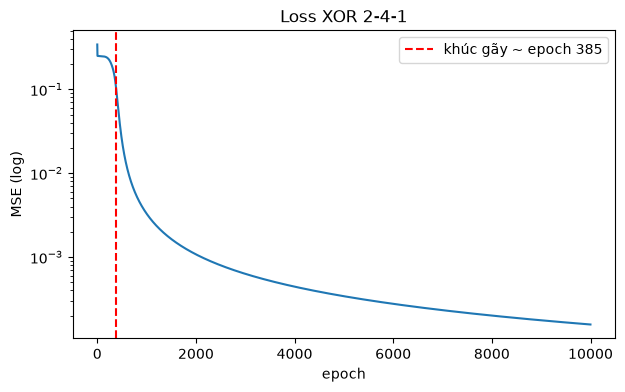

In [3]:
# XOR có thể kẹt cực tiểu cục bộ ở một số seed -> thử lần lượt đến khi đúng 100%
for seed in range(10):
    net = MLP([2, 4, 1], seed=seed)
    loss_hist = net.fit(XOR_X, XOR_Y, lr=2.0, epochs=10000)
    pred = net.forward(XOR_X)
    if ((pred > 0.5) == XOR_Y).all():
        break
print(f"seed={seed}  dự đoán = {np.round(pred.ravel(), 3)}  loss cuối = {loss_hist[-1]:.2e}")

# "Khúc gãy": loss nằm ở cao nguyên ~0.25 rất lâu rồi tụt đột ngột
knee = int(np.argmax(loss_hist < 0.1))
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(loss_hist)
ax.axvline(knee, color="r", ls="--", label=f"khúc gãy ~ epoch {knee}")
ax.set(xlabel="epoch", ylabel="MSE (log)", title="Loss XOR 2-4-1"); ax.legend()
fig.savefig(REPORTS / "xor_loss.png", dpi=150, bbox_inches="tight")

## Bước 4-5. Ranh giới quyết định: có tầng ẩn vs KHÔNG có tầng ẩn

Không tầng ẩn: accuracy tốt nhất qua 20 seed = 75%


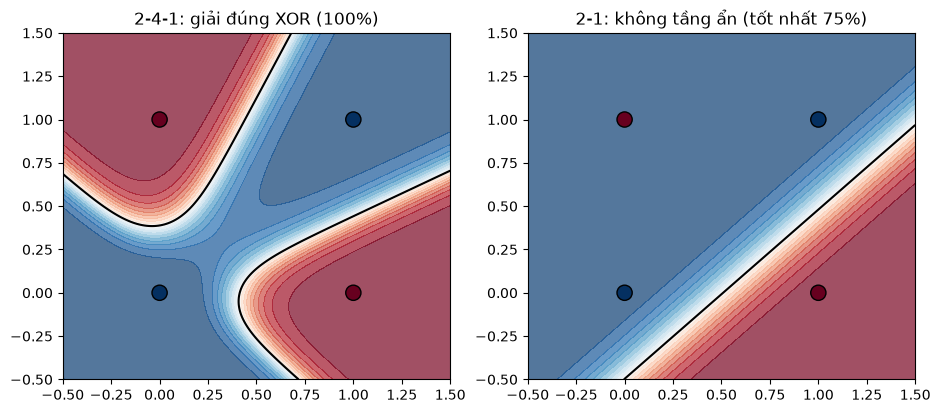

In [4]:
def ve_ranh_gioi(ax, model, title):
    g = np.linspace(-0.5, 1.5, 200)
    xx, yy = np.meshgrid(g, g)
    z = model.forward(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=20, cmap="RdBu_r", alpha=0.7)
    ax.contour(xx, yy, z, levels=[0.5], colors="k")
    ax.scatter(*XOR_X.T, c=XOR_Y.ravel(), cmap="RdBu_r", edgecolors="k", s=120)
    ax.set_title(title)

# Bước 5: 20 seed, mạng 2->1 không bao giờ vượt 75% (3/4 điểm) -> không giải được XOR
best_acc, best_net = -1, None
for seed in range(20):
    m = MLP([2, 1], seed=seed)
    m.fit(XOR_X, XOR_Y, lr=2.0, epochs=10000)
    acc = ((m.forward(XOR_X) > 0.5) == XOR_Y).mean()
    if acc > best_acc:
        best_acc, best_net = acc, m
print(f"Không tầng ẩn: accuracy tốt nhất qua 20 seed = {best_acc:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ve_ranh_gioi(axes[0], net, "2-4-1: giải đúng XOR (100%)")
ve_ranh_gioi(axes[1], best_net, f"2-1: không tầng ẩn (tốt nhất {best_acc:.0%})")
fig.savefig(REPORTS / "xor_boundary.png", dpi=150, bbox_inches="tight")